# Breast Cancer Gene Expression Analysis: Tumor vs Normal Tissue
**Computing Bioinformatics Group Project**  
**Dataset:** TCGA-BRCA (The Cancer Genome Atlas — Breast Invasive Carcinoma)  
**Group members:** Larry Seme, Dennis Kyalo, Joseph Manene, Timothy Muigai, Alex Ngigi

## Research question
Which genes are differentially expressed between breast cancer tissue and normal breast tissue, and can gene expression profiles distinguish the two sample types using machine learning?

## Objectives
1. Retrieve and document open-access TCGA-BRCA RNA-seq gene expression data and sample metadata.
2. Perform preprocessing, quality control, and exploratory data analysis.
3. Identify genes with differential expression between primary tumor and solid tissue normal samples, applying multiple-testing correction.
4. Train and evaluate machine-learning classifiers for tumor-versus-normal classification.
5. Interpret the findings biologically and state limitations.

## Hypothesis
Gene expression profiles differ between primary breast tumor and normal breast tissue, and these differences provide predictive information for classifying samples.

## Important reproducibility and interpretation notes
- This notebook queries the GDC API at run time; sample availability and returned file identifiers may change with GDC releases.
- It uses a subset of samples to keep a local run feasible. Results from a subset are not a substitute for a full-cohort analysis.
- The analysis uses a simple per-gene Mann–Whitney U test with Benjamini–Hochberg FDR correction as an exploratory differential-expression method. For publication-grade RNA-seq differential expression, use a count-aware method such as DESeq2/edgeR/limma-voom with appropriate design covariates.
- Machine learning is evaluated with a held-out stratified test set. Feature selection is fitted on the training set only to avoid leakage.
- This is a research/education exercise, not a clinical diagnostic tool.

## 1. Install and import dependencies
Run this cell first. Internet access is required to download data from GDC.

In [1]:
%pip -q install requests pandas numpy scipy statsmodels matplotlib seaborn scikit-learn tqdm

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, io, json, time, gzip, zipfile, warnings, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, RocCurveDisplay
)
from IPython.display import display

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

## 2. Data acquisition and source documentation

**Source:** NCI Genomic Data Commons (GDC), project TCGA-BRCA.  
**Project page:** https://portal.gdc.cancer.gov/projects/TCGA-BRCA  
**API documentation:** https://docs.gdc.cancer.gov/API/Users_Guide/  
**Access:** The notebook requests open-access STAR gene expression quantification files. It does not request controlled-access raw sequencing reads.

The code queries file metadata for primary tumor (`01`) and solid tissue normal (`11`) samples, then downloads a capped number of files from each group. It chooses one sample file per case where possible.

In [3]:
GDC_FILES_URL = "https://api.gdc.cancer.gov/files"
GDC_DATA_URL = "https://api.gdc.cancer.gov/data"
PROJECT_ID = "TCGA-BRCA"

# Limit samples for a practical local run. Increase gradually if your computer has
# sufficient RAM, storage, and internet bandwidth.
MAX_SAMPLES_PER_GROUP = 60

# GDC filter fields and values are based on the GDC data model.
def build_filter(sample_type):
    return {
        "op": "and",
        "content": [
            {"op": "in", "content": {"field": "cases.project.project_id", "value": [PROJECT_ID]}},
            {"op": "in", "content": {"field": "data_category", "value": ["Transcriptome Profiling"]}},
            {"op": "in", "content": {"field": "data_type", "value": ["Gene Expression Quantification"]}},
            {"op": "in", "content": {"field": "experimental_strategy", "value": ["RNA-Seq"]}},
            {"op": "in", "content": {"field": "analysis.workflow_type", "value": ["STAR - Counts"]}},
            {"op": "in", "content": {"field": "access", "value": ["open"]}},
            {"op": "in", "content": {"field": "cases.samples.sample_type", "value": [sample_type]}}
        ]
    }

fields = [
    "file_id", "file_name", "file_size", "cases.case_id",
    "cases.submitter_id", "cases.samples.sample_type",
    "cases.samples.submitter_id"
]

def query_gdc_files(sample_type, size=MAX_SAMPLES_PER_GROUP):
    payload = {
        "filters": build_filter(sample_type),
        "fields": ",".join(fields),
        "format": "JSON",
        "size": 500
    }
    response = requests.post(GDC_FILES_URL, json=payload, timeout=120)
    response.raise_for_status()
    hits = response.json()["data"]["hits"]
    records = []
    for hit in hits:
        cases = hit.get("cases", [])
        for case in cases:
            case_id = case.get("case_id")
            case_barcode = case.get("submitter_id")
            samples = case.get("samples", [])
            for sample in samples:
                if sample.get("sample_type") != sample_type:
                    continue
                records.append({
                    "file_id": hit["file_id"],
                    "file_name": hit.get("file_name"),
                    "file_size": hit.get("file_size"),
                    "case_id": case_id,
                    "case_barcode": case_barcode,
                    "sample_type": sample.get("sample_type"),
                    "sample_barcode": sample.get("submitter_id")
                })
    df = pd.DataFrame(records).drop_duplicates("file_id")
    # Avoid repeated files/cases where possible.
    df = df.sort_values("file_id").drop_duplicates("case_id")
    return df.head(size).reset_index(drop=True)

tumor_meta = query_gdc_files("Primary Tumor")
normal_meta = query_gdc_files("Solid Tissue Normal")

print("Primary tumor files found:", len(tumor_meta))
print("Solid tissue normal files found:", len(normal_meta))
display(tumor_meta.head(3))
display(normal_meta.head(3))

Primary tumor files found: 60
Solid tissue normal files found: 60


,file_id,file_name,file_size,case_id,case_barcode,sample_type,sample_barcode
0,0094f9d0-45ec-4aad-bca0-71c60bdd7113,cafc9e36-c5f0-45df-ad03-16210ff0d870.rna_seq.a...,4256688,4922cddc-575c-4b8a-8245-ce5f6876760c,TCGA-E9-A1R3,Primary Tumor,TCGA-E9-A1R3-01A
1,017d71aa-0999-4d8e-9cb4-88b9013e61eb,c6683fc6-49f4-4e53-94ac-251799c2c638.rna_seq.a...,4242722,dfe6db17-cf45-488e-bd3c-b8433d7343ca,TCGA-AR-A0TU,Primary Tumor,TCGA-AR-A0TU-01A
2,02a11397-2a9b-4dba-8c6a-6b9f0aa24372,9ccd787f-fde1-4fe6-a11f-d6203eaf9faf.rna_seq.a...,4256806,9964f447-92ad-4d1e-af20-11cf84fab7b0,TCGA-B6-A408,Primary Tumor,TCGA-B6-A408-01A


,file_id,file_name,file_size,case_id,case_barcode,sample_type,sample_barcode
0,040d00da-2bc9-49d4-bf6c-b4515b6a2bbf,d4f91697-1c39-4398-bf2f-85217a22ddff.rna_seq.a...,4241540,6b960b58-28e1-41c6-bd6e-7e669c6aa4ef,TCGA-BH-A18V,Solid Tissue Normal,TCGA-BH-A18V-11A
1,046fe29e-7c99-4093-8565-f2f205a00796,61f811cf-9dc1-4f48-ad62-c3ebfd1f0847.rna_seq.a...,4243915,c2aeee6c-ba10-4cf9-b560-c739580f7bf3,TCGA-BH-A0BM,Solid Tissue Normal,TCGA-BH-A0BM-11A
2,0972f396-9045-4faa-98f8-e8c3e02f9901,37157138-01ef-49a5-bc74-c45feaf411e2.rna_seq.a...,4257345,6a2972e3-cca9-47e5-aac0-b770f2399eeb,TCGA-BH-A1F2,Solid Tissue Normal,TCGA-BH-A1F2-11A


### Download and parse GDC STAR-count files

The GDC data endpoint downloads each selected file by UUID. The parser expects the tab-separated STAR Counts format with a `gene_id` column and an `unstranded` raw-count column. It keeps gene IDs and gene names for annotation and uses unstranded counts for the downstream exploratory analysis.

In [4]:
os.makedirs("data", exist_ok=True)

def download_count_file(file_id, file_name):
    path = os.path.join("data", file_name)
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    url = f"{GDC_DATA_URL}/{file_id}"
    with requests.get(url, stream=True, timeout=180) as r:
        r.raise_for_status()
        with open(path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
    return path

def parse_star_counts(path):
    # GDC STAR-count files are TSVs. Skip comment lines if present.
    df = pd.read_csv(path, sep="\t", comment="#")
    if "gene_id" not in df.columns:
        # fallback for format variants: first column is gene ID
        df = pd.read_csv(path, sep="\t", comment="#")
        df = df.rename(columns={df.columns[0]: "gene_id"})
    count_col = "unstranded"
    if count_col not in df.columns:
        candidates = [c for c in df.columns if "unstranded" in str(c).lower()]
        if not candidates:
            raise ValueError(f"No unstranded count column in {path}: {df.columns.tolist()}")
        count_col = candidates[0]
    gene_col = "gene_name" if "gene_name" in df.columns else None
    out = df[["gene_id", count_col] + ([gene_col] if gene_col else [])].copy()
    out = out.rename(columns={count_col: "count"})
    out["count"] = pd.to_numeric(out["count"], errors="coerce")
    out = out.dropna(subset=["gene_id", "count"])
    # Exclude STAR summary rows (N_unmapped, N_multimapping, etc.)
    out = out[~out["gene_id"].astype(str).str.startswith("N_")]
    return out

def download_group(meta, label):
    matrices = []
    gene_names = None
    downloaded = 0
    for row in meta.itertuples(index=False):
        try:
            path = download_count_file(row.file_id, row.file_name)
            parsed = parse_star_counts(path)
            sname = row.sample_barcode or row.case_barcode or row.file_id
            series = parsed.set_index("gene_id")["count"].rename(sname)
            matrices.append(series)
            if gene_names is None and "gene_name" in parsed.columns:
                gene_names = parsed.set_index("gene_id")["gene_name"]
            downloaded += 1
            if downloaded % 10 == 0:
                print(f"{label}: downloaded {downloaded}/{len(meta)}")
        except Exception as e:
            print(f"Skipping {row.file_name} due to: {e}")
    if not matrices:
        raise RuntimeError(f"No {label} count files downloaded. Check GDC availability or filters.")
    matrix = pd.concat(matrices, axis=1).fillna(0)
    return matrix, gene_names

tumor_counts, gene_names = download_group(tumor_meta, "Tumor")
normal_counts, gene_names_normal = download_group(normal_meta, "Normal")

# Align genes across samples and combine groups.
common_genes = tumor_counts.index.intersection(normal_counts.index)
tumor_counts = tumor_counts.loc[common_genes]
normal_counts = normal_counts.loc[common_genes]
counts = pd.concat([tumor_counts, normal_counts], axis=1)

labels = pd.Series(
    ["Tumor"] * tumor_counts.shape[1] + ["Normal"] * normal_counts.shape[1],
    index=counts.columns,
    name="sample_type"
)

print("Combined count matrix:", counts.shape, "(genes x samples)")
print(labels.value_counts())

Tumor: downloaded 10/60
Tumor: downloaded 20/60
Tumor: downloaded 30/60
Tumor: downloaded 40/60
Tumor: downloaded 50/60
Tumor: downloaded 60/60
Normal: downloaded 10/60
Skipping 930d7c02-c230-4d19-9247-74fb0e02d524.rna_seq.augmented_star_gene_counts.tsv due to: ('Connection aborted.', ConnectionResetError(10054, 'An existing connection was forcibly closed by the remote host', None, 10054, None))
Normal: downloaded 20/60
Normal: downloaded 30/60
Normal: downloaded 40/60
Normal: downloaded 50/60
Combined count matrix: (60660, 119) (genes x samples)
sample_type
Tumor     60
Normal    59
Name: count, dtype: int64


### Data dictionary
- `gene_id`: Ensembl gene identifier supplied in the GDC STAR-count file.
- `gene_name`: gene symbol when supplied by GDC.
- `count`: unstranded raw RNA-seq count for a gene in one sample.
- `sample_barcode`: GDC sample barcode.
- `sample_type`: primary tumor or solid tissue normal.
- `case_id` / `case_barcode`: GDC case identifier/barcode.

The sample counts printed above are the observed results from the current API query. Record them in the report after the notebook completes.

## 3. Preprocessing and quality control

We check missing values, zero-count genes, sample library sizes, and whether the two sample classes are represented. For visualization and machine learning, counts are transformed using `log2(CPM + 1)`. This is a simple exploratory transform, not a replacement for a count-aware differential expression method.

In [5]:
# Quality checks before transformation
print("Missing values in count matrix:", int(counts.isna().sum().sum()))
print("Negative counts:", int((counts < 0).sum().sum()))
print("Genes with zero counts in every sample:", int((counts.sum(axis=1) == 0).sum()))
print("Samples by class:")
display(labels.value_counts().rename_axis("class").to_frame("n_samples"))

library_sizes = counts.sum(axis=0).rename("library_size")
qc = pd.DataFrame({"sample": counts.columns, "sample_type": labels.values,
                  "library_size": library_sizes.values})
display(qc.groupby("sample_type")["library_size"].describe())

# Remove genes with zero counts in all samples.
counts = counts.loc[counts.sum(axis=1) > 0]

# CPM normalization for visualization / ML features.
cpm = counts.div(counts.sum(axis=0), axis=1) * 1e6
log_cpm = np.log2(cpm + 1)

print("After removing all-zero genes:", counts.shape)

Missing values in count matrix: 0
Negative counts: 0
Genes with zero counts in every sample: 4604
Samples by class:


,n_samples
class,
Tumor,60
Normal,59


,count,mean,std,min,25%,50%,75%,max
sample_type,,,,,,,,
Normal,59.0,5.788761e+07,1.306589e+07,29273747.0,49135780.50,57116595.0,66664533.50,86691458.0
Tumor,60.0,5.713110e+07,1.579364e+07,24791868.0,46426305.75,57041567.0,66899823.75,97239275.0


After removing all-zero genes: (56056, 119)


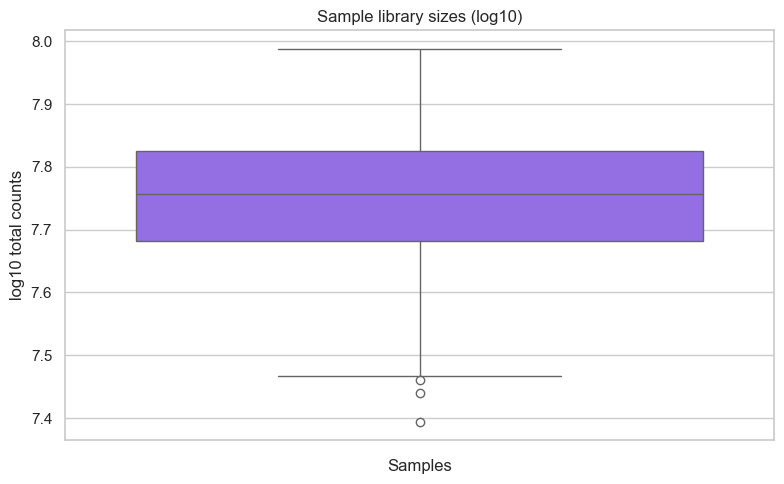

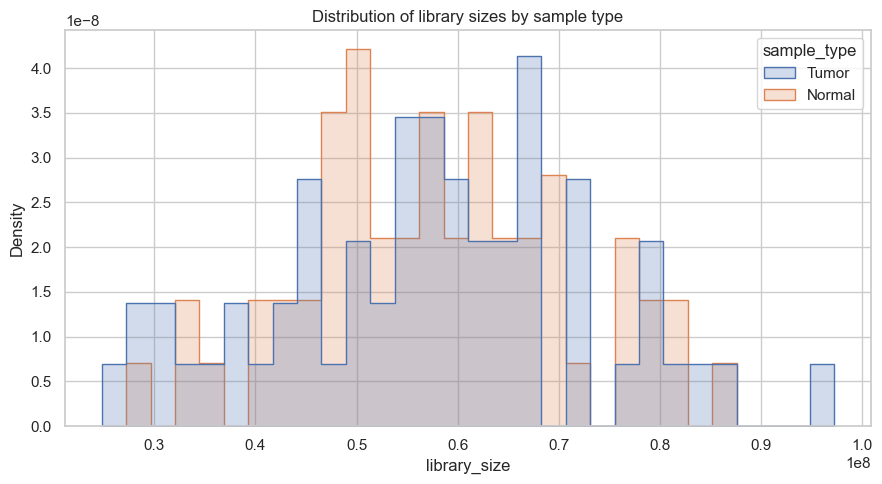

In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=np.log10(library_sizes + 1), color="#8b5cf6")
plt.title("Sample library sizes (log10)")
plt.ylabel("log10 total counts")
plt.xlabel("Samples")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.histplot(data=qc, x="library_size", hue="sample_type", bins=30, element="step", stat="density", common_norm=False)
plt.title("Distribution of library sizes by sample type")
plt.tight_layout()
plt.show()

**Interpretation prompt:** Describe whether library sizes vary substantially, whether either class has unusually low libraries, and whether any sample should be excluded. Do not remove samples merely because a plot looks different; document a defensible QC rule.

## 4. Exploratory data analysis

The notebook generates at least three informative plots:
1. Library size distribution.
2. PCA of log-CPM expression profiles.
3. Heatmap of the most variable genes.

These plots are descriptive. Separation in PCA does not by itself prove that a gene causes cancer or that the classifier will generalize clinically.

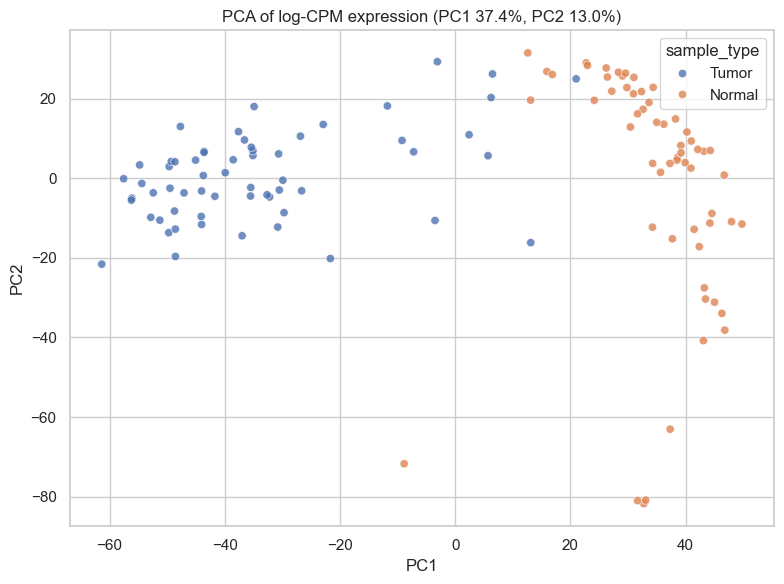

In [7]:
from sklearn.decomposition import PCA

# PCA on most variable genes to keep computation manageable.
var_genes = log_cpm.var(axis=1).sort_values(ascending=False).head(1000).index
X_pca = log_cpm.loc[var_genes].T
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_pca)
pca_df = pd.DataFrame(pcs, columns=["PC1", "PC2"], index=X_pca.index)
pca_df["sample_type"] = labels.loc[pca_df.index]

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="sample_type", alpha=0.8)
plt.title(f"PCA of log-CPM expression (PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%})")
plt.tight_layout()
plt.show()

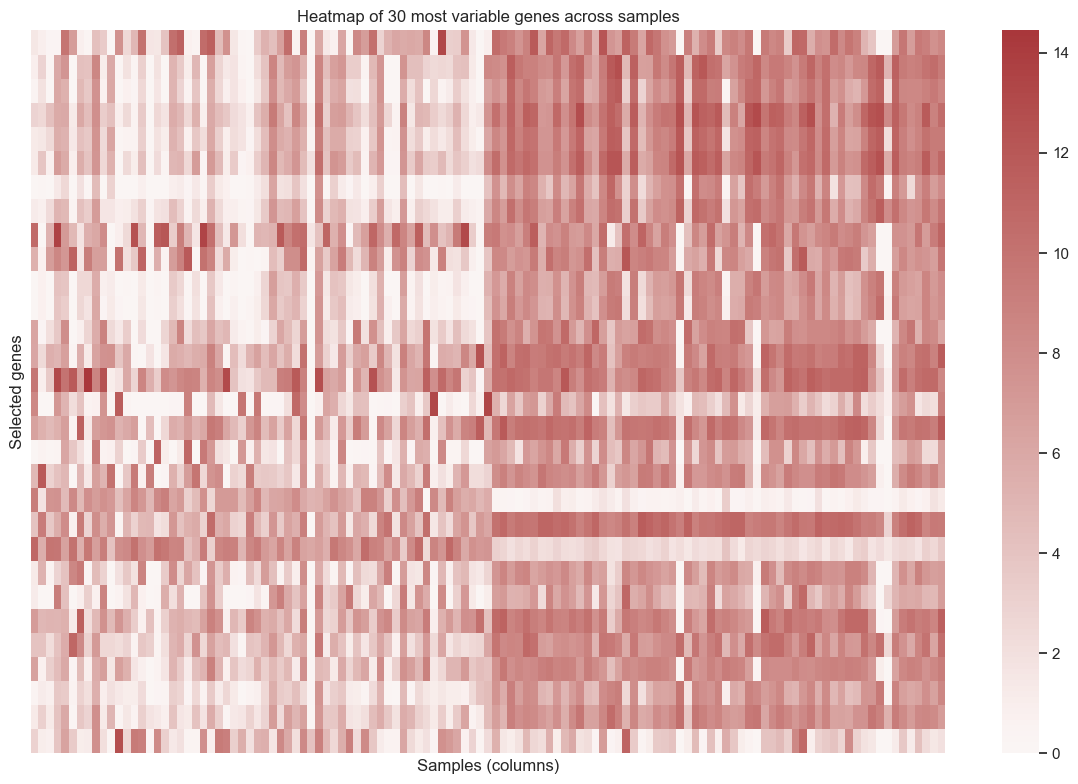

In [8]:
top_var = log_cpm.var(axis=1).sort_values(ascending=False).head(30).index
plt.figure(figsize=(12, 8))
sns.heatmap(log_cpm.loc[top_var], cmap="vlag", center=0, xticklabels=False, yticklabels=False)
plt.title("Heatmap of 30 most variable genes across samples")
plt.xlabel("Samples (columns)")
plt.ylabel("Selected genes")
plt.tight_layout()
plt.show()

**Interpretation prompt:** Note whether samples tend to group by tumor/normal status, whether there is overlap, and whether the pattern may be affected by sample size or technical variation.

## 5. Core analysis: exploratory differential expression

For each gene, compare log-CPM values in primary tumor versus solid tissue normal samples using a two-sided Mann–Whitney U test. Apply Benjamini–Hochberg correction across tested genes. Report the log2 mean-expression difference and adjusted p-value.

**Caveat:** This is an educational exploratory analysis. Count-aware RNA-seq differential expression packages (e.g., DESeq2, edgeR, limma-voom) are preferable for rigorous inference and covariate modeling.

In [9]:
tumor_samples = labels[labels == "Tumor"].index
normal_samples = labels[labels == "Normal"].index

results = []
for gene_id, row in log_cpm.iterrows():
    a = row.loc[tumor_samples].values
    b = row.loc[normal_samples].values
    if len(a) < 2 or len(b) < 2:
        continue
    try:
        stat, pval = mannwhitneyu(a, b, alternative="two-sided")
    except ValueError:
        pval = 1.0
    results.append({
        "gene_id": gene_id,
        "mean_logCPM_tumor": float(np.mean(a)),
        "mean_logCPM_normal": float(np.mean(b)),
        "log2_mean_difference": float(np.mean(a) - np.mean(b)),
        "p_value": float(pval)
    })

de = pd.DataFrame(results)
de["FDR"] = multipletests(de["p_value"], method="fdr_bh")[1]
if gene_names is not None:
    de["gene_name"] = de["gene_id"].map(gene_names)
elif gene_names_normal is not None:
    de["gene_name"] = de["gene_id"].map(gene_names_normal)
else:
    de["gene_name"] = de["gene_id"]

de = de.sort_values("FDR").reset_index(drop=True)
display(de.head(20))
print("Genes tested:", len(de))
print("Genes with FDR < 0.05:", int((de["FDR"] < 0.05).sum()))

,gene_id,mean_logCPM_tumor,mean_logCPM_normal,log2_mean_difference,p_value,FDR,gene_name
0,ENSG00000167434.10,0.389761,4.108879,-3.719118,8.307119e-20,4.149006e-16,CA4
1,ENSG00000158186.13,4.785601,7.088264,-2.302663,4.689598e-20,4.149006e-16,MRAS
2,ENSG00000168079.17,1.380890,6.189895,-4.809005,5.710812e-20,4.149006e-16,SCARA5
3,ENSG00000161649.13,1.221226,5.989295,-4.768069,7.656440e-20,4.149006e-16,CD300LG
4,ENSG00000136158.12,3.522606,6.074810,-2.552204,8.881845e-20,4.149006e-16,SPRY2
5,ENSG00000149090.12,2.451543,6.196676,-3.745133,5.998713e-20,4.149006e-16,PAMR1
6,ENSG00000170145.5,5.383445,7.482255,-2.098810,6.300952e-20,4.149006e-16,SIK2
7,ENSG00000170153.11,3.045651,5.970797,-2.925146,7.667914e-20,4.149006e-16,RNF150
8,ENSG00000099953.10,7.702350,2.415983,5.286366,3.318445e-20,4.149006e-16,MMP11
9,ENSG00000248869.7,0.132933,1.365076,-1.232143,6.628895e-20,4.149006e-16,LINC02511


Genes tested: 56056
Genes with FDR < 0.05: 20300


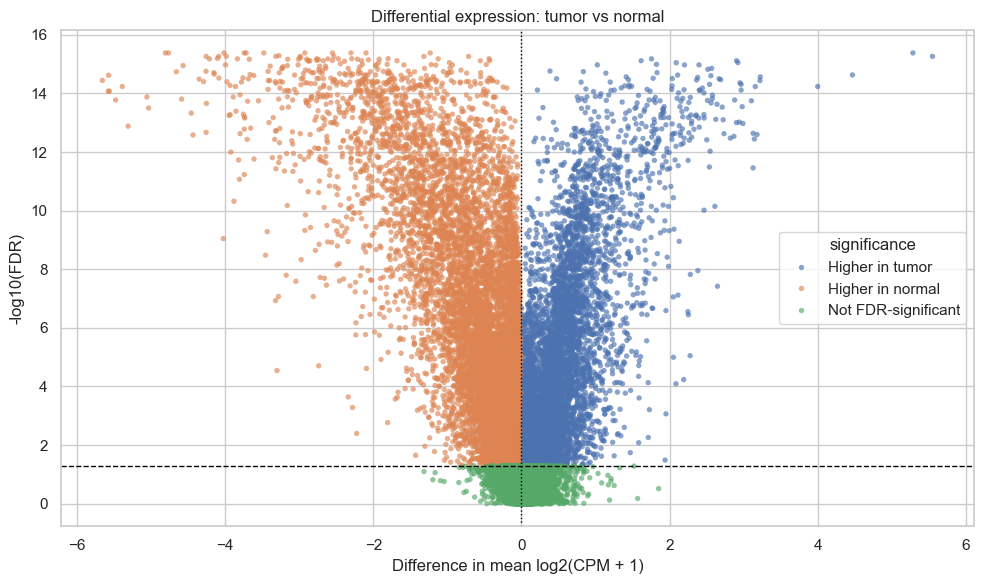

Saved differential_expression_results.csv


In [10]:
# Volcano plot
de["neglog10_FDR"] = -np.log10(de["FDR"].clip(lower=1e-300))
de["significance"] = np.where(
    (de["FDR"] < 0.05) & (de["log2_mean_difference"] > 0), "Higher in tumor",
    np.where((de["FDR"] < 0.05) & (de["log2_mean_difference"] < 0), "Higher in normal", "Not FDR-significant")
)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=de, x="log2_mean_difference", y="neglog10_FDR", hue="significance",
                hue_order=["Higher in tumor", "Higher in normal", "Not FDR-significant"],
                s=15, alpha=0.65, linewidth=0)
plt.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=1)
plt.axvline(0, linestyle=":", color="black", linewidth=1)
plt.title("Differential expression: tumor vs normal")
plt.xlabel("Difference in mean log2(CPM + 1)")
plt.ylabel("-log10(FDR)")
plt.tight_layout()
plt.show()

# Save table for reporting.
de.to_csv("differential_expression_results.csv", index=False)
print("Saved differential_expression_results.csv")

### Biological interpretation
Use the ranked genes to identify candidate genes with large expression differences and low FDR. Follow up using reputable resources such as:
- GeneCards: https://www.genecards.org/
- NCBI Gene: https://www.ncbi.nlm.nih.gov/gene/
- Enrichr: https://maayanlab.cloud/Enrichr/
- Gene Ontology: https://geneontology.org/

Do not claim a pathway is enriched unless a pathway-enrichment analysis has actually been run. For a stronger version, export the FDR-significant gene list and perform GO/KEGG enrichment, documenting the database and adjusted p-values.

## 6. Machine learning: tumor vs normal classification

The target is `Tumor` vs `Normal`. The model uses log-CPM expression features. The data is split into stratified train and test sets. Feature selection and scaling are fit on the training data only through a pipeline.

Models:
- Logistic Regression (baseline)
- Random Forest

Metrics:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion matrix

The models are educational classifiers of the dataset sample labels, not clinically validated diagnostic models.

In [11]:
# Samples are rows, genes are columns.
X = log_cpm.T.copy()
y = labels.loc[X.index].map({"Normal": 0, "Tumor": 1}).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

# Select the 500 highest-variance genes using training data only.
# This selection is performed before model fitting but only on training samples.
train_variances = X_train.var(axis=0)
selected_features = train_variances.sort_values(ascending=False).head(min(500, X_train.shape[1])).index

X_train_sel = X_train[selected_features]
X_test_sel = X_test[selected_features]

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE,
            min_samples_leaf=2, n_jobs=-1
        ))
    ])
}

metrics = []
fitted_models = {}
for name, model in models.items():
    model.fit(X_train_sel, y_train)
    fitted_models[name] = model
    pred = model.predict(X_test_sel)
    proba = model.predict_proba(X_test_sel)[:, 1]
    metrics.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, proba)
    })

metrics_df = pd.DataFrame(metrics).sort_values("ROC_AUC", ascending=False)
display(metrics_df)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333,0.995556
1,Random Forest,0.933333,0.933333,0.933333,0.933333,0.995556


Best model by test ROC-AUC: Logistic Regression
              precision    recall  f1-score   support

      Normal       0.93      0.93      0.93        15
       Tumor       0.93      0.93      0.93        15

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



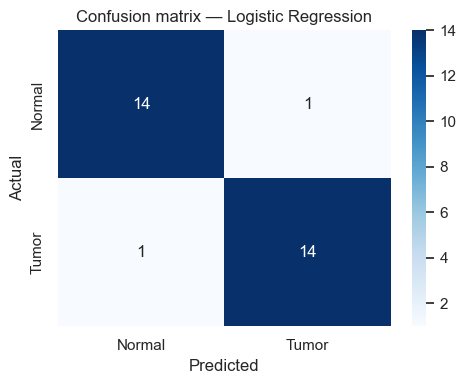

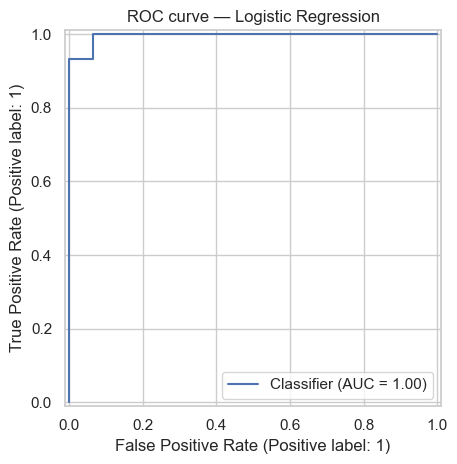

In [12]:
best_name = metrics_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
best_pred = best_model.predict(X_test_sel)
best_proba = best_model.predict_proba(X_test_sel)[:, 1]

print("Best model by test ROC-AUC:", best_name)
print(classification_report(y_test, best_pred, target_names=["Normal", "Tumor"], zero_division=0))

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Tumor"], yticklabels=["Normal", "Tumor"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, best_proba)
plt.title(f"ROC curve — {best_name}")
plt.tight_layout()
plt.show()

### Machine-learning interpretation
Record the observed metrics from the notebook output. Explain:
- Which model performed better on the held-out test set?
- Did the model make false-positive or false-negative predictions?
- Is the sample size adequate for reliable generalization?
- Why is external validation needed before any clinical use?

Avoid claiming clinical readiness or causal inference.

## 7. Biological interpretation and discussion

Use the actual output tables and plots to discuss:
- Whether tumor and normal samples differ in expression patterns.
- Which genes have the strongest observed expression differences and whether they remain significant after FDR correction.
- Whether the PCA/heatmap patterns align with the classification results.
- What selected genes are known to do, using cited biological resources.
- Whether the analysis supports the hypothesis, partially supports it, or is inconclusive.

Suggested discussion structure:
1. Main findings.
2. Biological meaning of selected genes.
3. Comparison with published breast cancer findings.
4. Limitations and alternative explanations.

## 8. Conclusions and limitations

### Conclusions
Write one conclusion for each objective, based only on observed outputs:
1. Data retrieval and quality: [report sample/gene counts and QC].
2. Differential expression: [report significant gene count and examples].
3. Classification: [report test metrics and best model].
4. Biological interpretation: [summarize supported insights].

### Limitations
- Sample subset rather than full TCGA-BRCA cohort.
- Potential confounding by age, tumor subtype, stage, batch, and other variables.
- Exploratory Mann–Whitney testing is not the preferred count-aware RNA-seq method.
- The train/test split may be unstable with a small sample subset.
- No independent external validation dataset.
- Classification performance is not evidence of clinical diagnostic utility.

### Future work
- Use all eligible TCGA-BRCA open-access samples.
- Apply DESeq2/edgeR/limma-voom with covariates.
- Perform GO/KEGG pathway enrichment.
- Validate selected genes and classifier on an independent cohort.

In [13]:
# Export key outputs to files for the report/presentation.
metrics_df.to_csv("model_metrics.csv", index=False)
qc.to_csv("sample_qc.csv", index=False)
print("Exported: differential_expression_results.csv, model_metrics.csv, sample_qc.csv")

Exported: differential_expression_results.csv, model_metrics.csv, sample_qc.csv


## References and data citation
1. National Cancer Institute, Genomic Data Commons (GDC). TCGA-BRCA project: https://portal.gdc.cancer.gov/projects/TCGA-BRCA
2. GDC API documentation: https://docs.gdc.cancer.gov/API/Users_Guide/
3. The Cancer Genome Atlas (TCGA) Research Network. Comprehensive molecular portraits of human breast tumours. *Nature* (2012). https://doi.org/10.1038/nature11412
4. Benjamini, Y. and Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B*, 57(1), 289–300.

**Data access date:** Record the date on which you run this notebook.  
**Notebook authoring:** [Group name / course details to be completed by students].